# 03 - Volume of Clay (Vcl)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/03_clay_volume.ipynb)

**Part A - Petrophys Curriculum - Foundations**

The volume of clay (Vcl, sometimes written Vsh for volume of shale) is one of the
most consequential intermediate curves in a petrophysical interpretation. It drives
the split between *total* and *effective* porosity, controls the shale term in every
shaly-sand saturation model, and defines the net-reservoir flag. Getting Vcl wrong
propagates into every downstream number.

This lesson builds Vcl from the ground up using `petrophys.interpretation.clay_volume`.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- Read the clay volumes `pp.interpret` computes - `VCL_GR`, `VCL_SP`, `VCL_ND` and the
  combined `VCL` - and the decisions its trace records.
- Explain how the **GR endpoints** (`GR_clean`, `GR_clay`) are picked objectively from
  percentiles of the log, and set your own with `gr_min` / `gr_max`.
- Compare the **linear gamma-ray index** (IGR) with the four common **non-linear GR
  corrections** (Larionov tertiary, Larionov older, Stieber, Clavier) by changing
  `gr_method`, and explain *why* the non-linear transforms exist: the linear index
  systematically **over-estimates** clay.
- Understand the **SP** and **neutron-density** clay volumes (the clay point `nd_clay`),
  and when each is valid.
- Compare combine rules with `calculate_vcl`, read the **clay resistivity** Rcl of a run,
  and classify the result with `classify_vcl`.

## Why this matters (the physics)

Clay minerals carry no effective (movable-fluid) porosity but are electrically
conductive and radioactive. Three independent log responses let us "see" clay:

| Indicator | Physical basis | Failure mode |
|-----------|----------------|--------------|
| **Gamma ray** | Clays concentrate K, U, Th | Misreads radioactive sands (feldspar, mica) or non-radioactive kaolinite |
| **SP** | Membrane potential between shale and permeable sand | Suppressed when Rmf ≈ Rw (and by hydrocarbons, thin beds, KCl or oil-based mud); reversed when the formation water is fresher than the filtrate |
| **Neutron-Density** | Clay-bound water raises NPHI while density stays high | Distorted by gas (crossover) |

Because each has a different blind spot, robust workflows compute several and combine
them - which is what the clay-volume step of `pp.interpret` does.

### The gamma-ray index

The starting point for every GR method is the linear **gamma-ray index**:

$$ I_{GR} = \frac{GR - GR_{clean}}{GR_{clay} - GR_{clean}} $$

Taking $V_{cl} = I_{GR}$ (the *linear* method) assumes clay content is proportional
to radioactivity. In reality the relationship is concave - a little clay raises GR a
lot - so the linear index **over-states** clay. The non-linear equations correct for
this.

### Prerequisites

This lesson assumes you have worked through **lesson 01 (data access)** and
**lesson 02 (quality control)**. We use the bundled clastic well **30/6-5** from
the GeoLink dataset (depths in metres) and report statistics over its Brent Group,
2841-2958 m. The setup cell hides only the SWC/SOC core-saturation unit note explained
in lessons 00 and 02.

In [2]:
import warnings
import pandas as pd
import petrophys as pp

warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")
well = pp.read(pp.sample("30_6-5"))

## Step 1 - Picking the GR endpoints objectively

`GR_clean` (clean-sand baseline) and `GR_clay` (pure-shale reading) are the two most
important parameters in a GR clay model. Reading them off a plot by eye is subjective
and hard to reproduce. A robust, defensible choice is to use **percentiles** of the
GR log:

- `GR_clean` = a **low** percentile (P5): the cleanest sands in the interval.
- `GR_clay`  = a **high** percentile (P95): the most shale-rich beds.

Using P5/P95 rather than the absolute min/max rejects spikes and washout artefacts.
This is what `pp.interpret` does when you set no endpoints. Its trace records every
decision of the clay-volume step (`vclay`); the cell lists them.

In [3]:
result = pp.interpret(well)
result.step("vclay").decisions

['GR_min = 21.6 (auto, P5 of GR)',
 'GR_max = 115.3 (auto, P95 of GR)',
 'Gamma-ray clay input: GR',
 'GR method: linear',
 'SP method: enabled',
 'N-D method: enabled',
 'SP_clean = 43.2 (auto, P5 of SP)',
 'SP_shale = 111.6 (auto, P95 of SP)',
 'Applied GR endpoints: 20 to 115.313 API',
 'GR bound (nearly flat GR guard): the clean GR pick 21.6 API was lowered to 20',
 'Final VCL = min(GR, ND) at each depth, range: 0.000 - 1.000',
 'VCL_SP is reported but left out of the minimum: SP baselines picked over the whole log mostly measure SP baseline drift, so it only fills depths with no GR or N-D value. Set both sp_min and sp_max to include it; they apply to the whole log, so only for an SP without baseline drift',
 'N-D clean line (sandstone): RHOB 2.65 g/cm3 at NPHI -0.02 to RHOB 1.99 g/cm3 at NPHI 0.38',
 'N-D clay point: RHOB 2.346 g/cm3, NPHI 0.409, the median of 816 good-hole shale-lithology samples at 2461.85-3544.96 m',
 "VCL_ND undefined at 8499 samples with NPHI above 0.409, bey

The automatic picks are P5 = 21.6 API and P95 = 115.3 API. Endpoints picked
*automatically* are then bounded to `GR_clean <= 20` and `GR_clay >= 100` API, a guard
against a nearly flat GR with no real shale or clean bed, so the clean pick is lowered
to 20 API and the run uses 20 to 115.3 API. Endpoints you set with `gr_min` and `gr_max`
(for example from a crossplot or core) are used as given. The same trace also records
the SP baselines and the neutron-density clay point that Steps 3 and 4 explain.

## Step 2 - The five GR methods, side by side

The `gr_method` setting chooses the transform from $I_{GR}$ to clay volume:

| `gr_method` | Equation | Use when |
|----------|----------|----------|
| `linear` (default) | $V_{cl}=I_{GR}$ | Quick-look; **over-estimates** clay |
| `larionov_tertiary` | $0.083\,(2^{3.7 I_{GR}}-1)$ | Young, unconsolidated (Tertiary) rocks |
| `larionov_older` | $0.33\,(2^{2 I_{GR}}-1)$ | Older, consolidated / Mesozoic rocks |
| `steiber` | $I_{GR}/(3-2 I_{GR})$ | General clastic correction |
| `clavier` | $1.7-\sqrt{3.38-(I_{GR}+0.7)^2}$ | General clastic correction |

All four non-linear curves lie **below** the linear line for the same GR - they
reduce the clay over-estimate. For a mid-range reading of $I_{GR}=0.5$ the linear
method returns Vcl = 0.50, Larionov older 0.33, Clavier 0.31, Stieber 0.25 and
Larionov tertiary 0.22. That is a large difference in a shaly sand: it can move an
interval from "non-reservoir" to "pay". Larionov *tertiary* is the most aggressive
correction (steepest curvature) and suits young, poorly consolidated sediments;
Larionov *older* is milder and suits consolidated rocks.

One interpretation per method shows the effect on 30/6-5; the table gives the
statistics of `VCL_GR` over the Brent Group.

In [4]:
methods = ["linear", "larionov_tertiary", "larionov_older", "steiber", "clavier"]
runs = {method: pp.interpret(well, gr_method=method) for method in methods}
pd.concat({method: run.statistics("VCL_GR", top=2841, bottom=2958) for method, run in runs.items()})

,,unit,samples,mean,p10,median,p90
linear,VCL_GR,v/v,768,0.419364,0.108921,0.340668,0.861332
larionov_tertiary,VCL_GR,v/v,768,0.239364,0.026748,0.115846,0.672862
larionov_older,VCL_GR,v/v,768,0.310258,0.053788,0.199196,0.759152
steiber,VCL_GR,v/v,768,0.258223,0.039150,0.146924,0.674325
clavier,VCL_GR,v/v,768,0.294169,0.049047,0.184411,0.729312


#### Interpretation

Every non-linear transform gives a lower mean Vcl than the linear gamma-ray index:
0.419 linear against 0.310 Larionov older, 0.294 Clavier, 0.258 Stieber and 0.239
Larionov tertiary over the Brent Group. This is the expected correction when the
linear index overstates clay volume. The medians differ even more (0.341 linear,
0.116 Larionov tertiary), because the correction is strongest at low and mid-range
$I_{GR}$, where the clean sands sit.

### Depth comparison

`pp.plot` with several results and `curves=` draws them in one figure, one line per
result; given a mapping, it labels each line by its key, here the method. The window, 2800-3000 m, brackets the Brent Group: the corrections
pull the clean sands of the Ness Formation (around 2845 m) and the Etive Formation
(about 2868-2890 m and 2915-2938 m) close to zero, while
all five methods agree in the shales at the top of the scale.

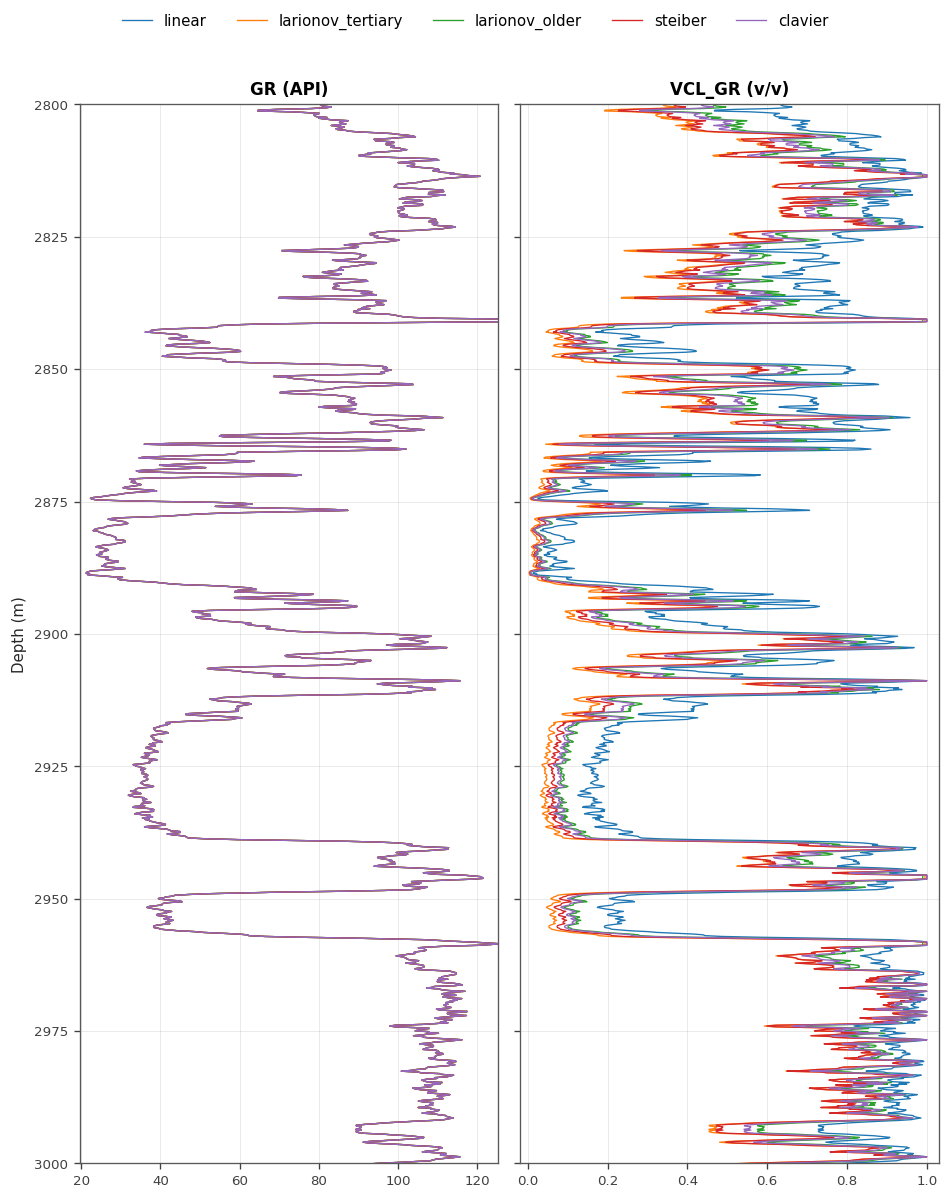

In [5]:
pp.plot(runs, curves=["GR", "VCL_GR"], top=2800, bottom=3000, figsize=(8, 10))

## Step 3 - Clay volume from SP

The SP log gives an independent clay indicator via the shale-fraction of the SP
deflection:

$$ V_{cl}^{SP} = \frac{SP_{clean} - SP}{SP_{clean} - SP_{shale}} $$

`pp.interpret` writes it as `VCL_SP`. The **clean-sand** line (`sp_max`, the static SP, the
greatest deflection) and the **shale baseline** (`sp_min`) are picked from percentiles
again: P5 for clean sand, P95 for the shale line - 43.2 mV and 111.6 mV in the trace above.
The two names follow the deflection, not the size of the number: on this log the clean
line `sp_max` is the lower value (43.2 mV) and the shale baseline `sp_min` the higher
(111.6 mV), and the run warns when the two look swapped.

**Caveat:** SP is unreliable with fresh formation water, KCl / oil-based mud, or in
thin beds, and its baseline drifts with depth. Two constant lines picked over the whole
log mostly measure that drift, not shaliness, so `VCL_SP` is reported but joins the
combined `VCL` only when you set both `sp_min` and `sp_max` for an SP without baseline
drift. Treat it as a cross-check, not a primary curve.

## Step 4 - Clay volume from neutron density (the 3-point equation)

In a water-bearing shaly sand, clay-bound water pushes the **neutron** porosity up
while **density** stays high, so shale plots away from the clean sandstone line.
`VCL_ND` is a closed-form equation evaluated at every sample: the fractional distance of
the (NPHI, RHOB) pair from the clean line toward a clay point in density-neutron space.
Nothing is read off a plot; the three endpoints fully determine the result.

For a clastic well the clean line is the **sandstone** line, from RHOB 2.65 g/cm3 at
NPHI -0.02 (quartz) to RHOB 1.99 g/cm3 at NPHI 0.38. `pp.interpret` picks the clay
point in the well's own good-hole shales - the median RHOB and NPHI of at least 20
shale-lithology samples, else of the samples with VCL_GR > 0.9, else (2.62, 0.38). In
30/6-5 the trace above shows RHOB 2.346 g/cm3, NPHI 0.409 from 816 shale samples. A point
less than 0.10 v/v of neutron above the clean line cannot tell shale from clean rock, so
VCL_ND is then reported but left out of VCL, with a warning. VCL_ND is also left
undefined where the neutron reads above both the clean line's end point and the clay
point: outside the triangle the three-point formula interpolates in, where undercompacted
mudstone often plots (Crain, *The Log Analysis Handbook*, 1986).

`nd_clay=(RHOB, NPHI)` sets the clay point yourself. The cell compares `VCL_ND` over the
Brent Group with the picked point and with the generic point (2.62, 0.38).

In [6]:
result = runs["larionov_older"]
generic_point = pp.interpret(well, gr_method="larionov_older", nd_clay=(2.62, 0.38))
pd.concat({"clay point from the shales": result.statistics("VCL_ND", top=2841, bottom=2958),
           "clay point (2.62, 0.38)": generic_point.statistics("VCL_ND", top=2841, bottom=2958)})

,,unit,samples,mean,p10,median,p90
clay point from the shales,VCL_ND,v/v,728,0.390374,0.003053,0.279902,0.95457
"clay point (2.62, 0.38)",VCL_ND,v/v,718,0.257715,0.001480,0.177695,0.61350


The generic point is denser and further from the clean line than the 30/6-5 shales, so
the same (NPHI, RHOB) pair sits a smaller fraction of the way to it: the Brent mean
VCL_ND drops from 0.390 to 0.258. The clay point is a calibration of the well, not a
constant.

### Comparing the three families

We have three independent clay estimates: GR (Larionov older, a sensible default
for this Jurassic clastic), SP, and N-D, plus the combined `VCL`. Plotted together they
show how well they agree and where they diverge, and the table compares them over the
Brent Group.

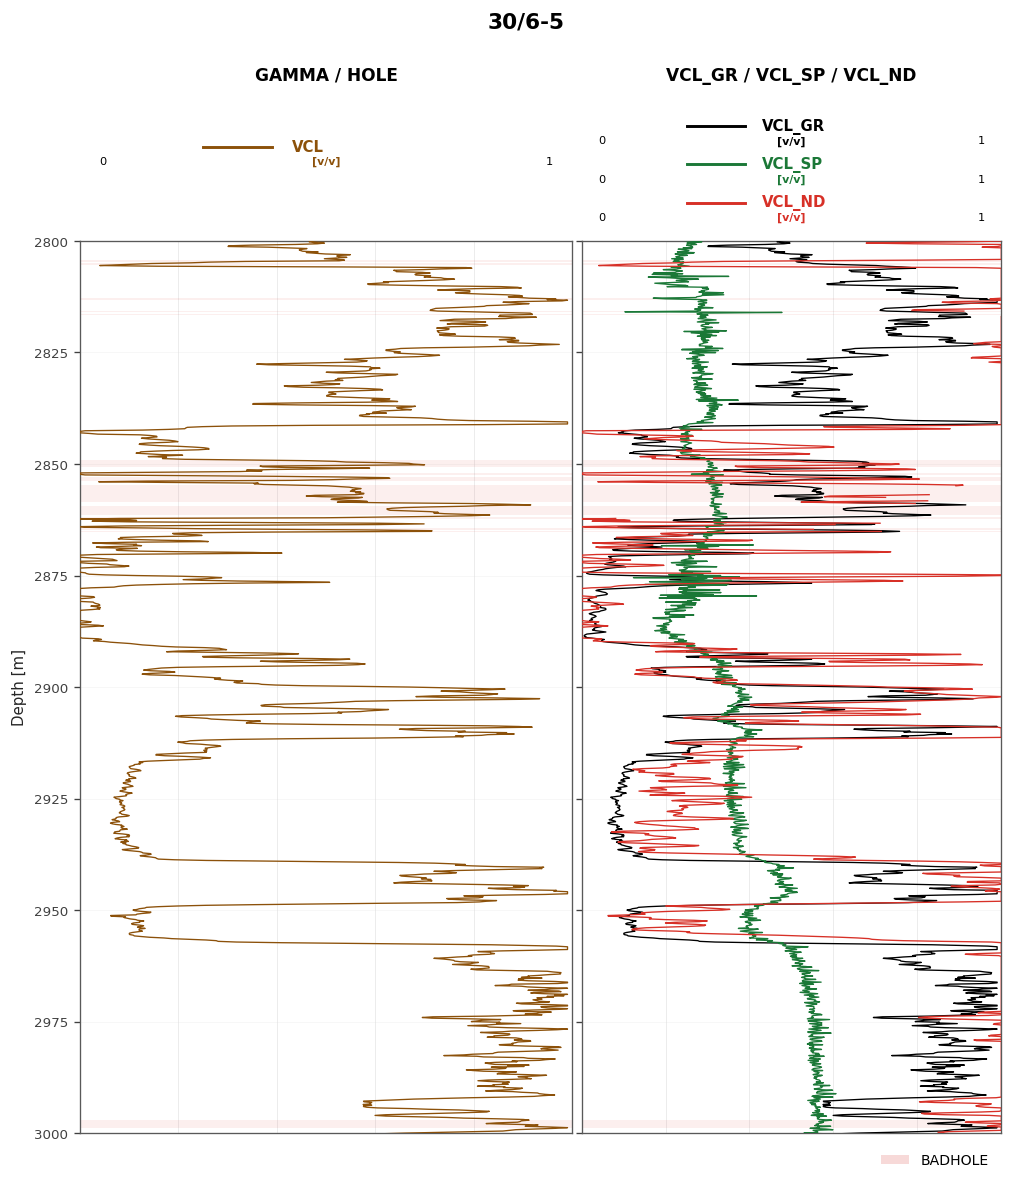

In [7]:
pp.plot(result, curves=["VCL_GR", "VCL_SP", "VCL_ND", "VCL"], top=2800, bottom=3000, figsize=(8, 10))

In [8]:
result.statistics(["VCL_GR", "VCL_SP", "VCL_ND", "VCL"], top=2841, bottom=2958)

,unit,samples,mean,p10,median,p90
VCL_GR,v/v,768,0.310258,0.053788,0.199196,0.759152
VCL_SP,v/v,768,0.335927,0.239314,0.343353,0.429459
VCL_ND,v/v,728,0.390374,0.003053,0.279902,0.954570
VCL,v/v,768,0.288155,0.010977,0.164844,0.753520


Over the Brent Group the SP estimate barely varies (P10-P90 0.24-0.43 against
0.05-0.76 for GR): its whole-log baselines flatten it, which is why it stays out of `VCL`.
GR and N-D agree on the clean sands and the shales, and `VCL`, the lower of the two at
each depth, has a mean of 0.288.

## Step 5 - Combining methods

`pp.interpret` combines by taking, at each depth, the **minimum** of the gamma-ray and
neutron-density estimates (the trace above says `Final VCL = min(GR, ND)`). The minimum
is simple and conservative against the over-reading of each indicator, but a spuriously
low reading can drag it below the true clay content.

`calculate_vcl(well, ...)` in `petrophys.interpretation.clay_volume` offers a second rule
for comparison:

- `combine='min'` (default): the **minimum** across methods at each depth.
- `combine='auto'`: neutron-density-primary, using GR where gas invalidates N-D or
  where N-D is unavailable, and SP only as a non-lowering cross-check.

It takes the same well and settings and returns a `VclResult` whose `method_used` says
which indicator won at each depth. The table counts the samples each indicator won under
each rule over the whole well. (`calculate_vcl` uses the generic clay point (2.62, 0.38)
rather than the point picked from the shales.)

In [9]:
from petrophys.interpretation.clay_volume import calculate_vcl

combined = {rule: calculate_vcl(well, gr_method="larionov_older", matrix="sandstone", combine=rule)
            for rule in ["min", "auto"]}
pd.DataFrame({rule: pd.Series(vcl.method_used).value_counts() for rule, vcl in combined.items()})

,min,auto
GR,18648,14712
ND,3528,7464


Under `min` the gamma ray wins at 18648 of 22176 samples and the neutron-density
estimate rarely does, so the combined curve follows the lower GR reading. Under `auto`
the neutron-density estimate anchors 7464 samples, and GR fills the other 14712: 4755
where the neutron log was not run (it covers only 79% of the hole, lesson 01) and about
9900 where the neutron reads above 0.38, outside the neutron-density triangle, so `VCL_ND`
is undefined there (Step 4). This is a good
illustration of why the combine rule is a real interpretation decision, not a
formality.

## Step 6 - Clay resistivity (Rcl)

Shaly-sand saturation models (Simandoux, Indonesia, dual-water) need a value for the
resistivity of the clay itself, `Rcl`. The `rcl` step of `pp.interpret` estimates it from
the **deep resistivity** of the shale samples, here those of the well's lithology log;
its trace records the source, and the result keeps the value in `rcl_computed` (ohm.m).

In [10]:
result.step("rcl").decisions, result.rcl_computed

(['Rcl = 2.91 ohm.m (median RT in shale lithology samples, n=1172)'],
 2.9059999999999997)

## Step 7 - Classifying the result

`classify_vcl` bins clay volume into three formation-quality categories:

- `CLEAN_FORMATION` : Vcl < 0.25
- `MODERATE_CLAY`   : 0.25 <= Vcl <= 0.50
- `SHALY_FORMATION` : Vcl > 0.50

The cell classifies the combined `VCL` of the Brent Group.

In [11]:
from petrophys.interpretation.clay_volume import classify_vcl

pd.Series(classify_vcl(result.well["VCL"].depth_slice(2841, 2958).data)).value_counts()

VclClassification.CLEAN_FORMATION    459
VclClassification.SHALY_FORMATION    190
VclClassification.MODERATE_CLAY      119
Name: count, dtype: int64

459 of the 768 Brent samples (60%) are clean, 119 moderately clayey and 190 shaly: the
Brent Group here is a stack of clean Ness and Etive sands separated by shale, silt and
coal beds (see the lithology track of lesson 00), not a uniformly shaly unit.

## Pitfalls and parameter choices

- **Endpoint picking dominates everything.** A 10-API error in `GR_clay` shifts the
  whole Vcl curve. Percentiles (P5/P95) give a reproducible first pass; refine against
  core or crossplots where available and set them with `gr_min` / `gr_max`.
- **Linear GR over-estimates clay.** `pp.interpret` defaults to `gr_method="linear"`
  and tempers it with the minimum against neutron-density; where the gamma ray carries
  the clay volume alone, choose Larionov (tertiary for young rocks, older for
  consolidated), Stieber, or Clavier before the result feeds volumetrics.
- **SP is fragile.** Discard it when Rmf ≈ Rw, with KCl/oil-based mud, thin beds or a
  drifting baseline: constant baselines picked over the whole log misread every
  interval where the baseline has moved.
- **N-D is distorted by gas.** In gas zones the neutron reads *low*, so N-D
  under-estimates clay - this is why `combine='auto'` falls back to GR there.
- **The clay point is a calibration.** Check the picked `nd_clay` against a
  neutron-density crossplot of the interval you evaluate.
- **Combine rule matters.** `min` is conservative but can under-read; `auto` anchors on
  the neutron-density response.

## Recap

- Vcl starts from the linear gamma-ray index $I_{GR}$ built off `GR_clean`/`GR_clay`
  endpoints, best chosen from **percentiles**; `pp.interpret` picks P5/P95 and records
  them in its trace.
- Non-linear transforms (**Larionov, Stieber, Clavier**, `gr_method`) all reduce the
  linear method's clay over-estimate; we saw it in the Brent statistics and the depth
  comparison.
- **SP** and **neutron-density** give independent estimates with different blind
  spots; `pp.interpret` combines GR and N-D with a minimum, and `calculate_vcl` compares
  `min` with `auto`.
- The `rcl` step gives the clay resistivity needed downstream, and `classify_vcl`
  bins the answer into clean / moderate / shaly.

## Try it yourself

> **Exercise 1.** Set the GR endpoints to P10/P90 instead of P5/P95:
> `pp.interpret(well, gr_method="larionov_older", gr_min=well["GR"].percentile(10),
> gr_max=well["GR"].percentile(90))`. How much does the Brent mean `VCL_GR` move?
>
> **Exercise 2.** Plot `method_used` of the two `calculate_vcl` results against depth
> (or count it over 2841-2958 m only). Where do the two rules diverge most?
>
> **Exercise 3.** Interpret the carbonate well `HW-3` (COSTA dataset) with
> `lithology_domain="carbonate"` and look at its `VCL_ND`. Why is the matrix choice
> essential here? (`pp.interpret` measures VCL_ND from the clean line of the matrix the
> run uses, so a carbonate run gets a limestone or dolomite line.)

## What's next

Clay volume feeds directly into porosity: the **effective** porosity is the total
porosity minus the clay-bound water we just quantified. Continue with
**lesson 04 - Porosity**, where the same interpretation splits total and effective
porosity with this Vcl curve.